# Implementation and Comparison of Extractive and Abstractive Text Summarization Techniques

## 1. Environment Setup and Library Imports


In [1]:
import nltk
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import pipeline

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

/Users/anshumaansoni/PycharmProjects/Natural Language Processing/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[nltk_data] Downloading package punkt to
[nltk_data]     /Users/anshumaansoni/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/anshumaansoni/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/anshumaansoni/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## 2. Dataset Selection and Input Text


In [2]:
text = """Artificial intelligence has transformed numerous industries by automating tasks that previously required human cognition. In healthcare, machine learning algorithms analyze medical images to detect diseases at earlier stages than traditional diagnostics. The financial sector utilizes predictive models to detect fraudulent transactions and optimize investment portfolios in real time. Autonomous vehicles rely on computer vision and sensor fusion to navigate complex road environments safely. Natural language processing models power chatbots and translation tools, enabling smoother communication across linguistic boundaries. However, the rapid advancement of artificial intelligence raises ethical concerns regarding data privacy and algorithmic bias. Many models operate as black boxes, making it difficult for researchers to interpret their decision-making processes. Job displacement remains another significant challenge as automation impacts various segments of the workforce. Ensuring transparency, fairness, and accountability in AI development is essential for building public trust. Collaborative efforts between researchers, policymakers, and industry leaders are necessary to guide the responsible deployment of these technologies."""

print("Raw text length:", len(text), "characters")
print()
print("Selected Text:")
print(text)

Raw text length: 1246 characters

Selected Text:
Artificial intelligence has transformed numerous industries by automating tasks that previously required human cognition. In healthcare, machine learning algorithms analyze medical images to detect diseases at earlier stages than traditional diagnostics. The financial sector utilizes predictive models to detect fraudulent transactions and optimize investment portfolios in real time. Autonomous vehicles rely on computer vision and sensor fusion to navigate complex road environments safely. Natural language processing models power chatbots and translation tools, enabling smoother communication across linguistic boundaries. However, the rapid advancement of artificial intelligence raises ethical concerns regarding data privacy and algorithmic bias. Many models operate as black boxes, making it difficult for researchers to interpret their decision-making processes. Job displacement remains another significant challenge as automation impacts 

## 3. Text Preprocessing and Sentence Tokenization


In [3]:
sentences = sent_tokenize(text)
print("Total sentences extracted:", len(sentences))

stop_words = set(stopwords.words('english'))
cleaned_sentences = []

for s in sentences:
    tokens = [w.lower() for w in word_tokenize(s) if w.isalnum() and w.lower() not in stop_words]
    cleaned_sentences.append(" ".join(tokens))

for i, s in enumerate(cleaned_sentences):
    print(f"Sentence {i + 1}: {s}")

Total sentences extracted: 10
Sentence 1: artificial intelligence transformed numerous industries automating tasks previously required human cognition
Sentence 2: healthcare machine learning algorithms analyze medical images detect diseases earlier stages traditional diagnostics
Sentence 3: financial sector utilizes predictive models detect fraudulent transactions optimize investment portfolios real time
Sentence 4: autonomous vehicles rely computer vision sensor fusion navigate complex road environments safely
Sentence 5: natural language processing models power chatbots translation tools enabling smoother communication across linguistic boundaries
Sentence 6: however rapid advancement artificial intelligence raises ethical concerns regarding data privacy algorithmic bias
Sentence 7: many models operate black boxes making difficult researchers interpret processes
Sentence 8: job displacement remains another significant challenge automation impacts various segments workforce
Sentence 9

## 4. Sentence Vectorization Using TF-IDF


In [4]:
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(cleaned_sentences)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (10, 112)


## 5. Sentence Similarity Computation Using Cosine Similarity


In [5]:
similarity_matrix = cosine_similarity(tfidf_matrix, tfidf_matrix)

print("Similarity matrix dimensions:", similarity_matrix.shape)
print()
print("Pairwise Cosine Similarity Matrix:")
print(np.round(similarity_matrix, 2))

Similarity matrix dimensions: (10, 10)

Pairwise Cosine Similarity Matrix:
[[1.   0.   0.   0.   0.   0.13 0.   0.   0.   0.  ]
 [0.   1.   0.06 0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.06 1.   0.   0.04 0.   0.05 0.   0.   0.  ]
 [0.   0.   0.   1.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.04 0.   1.   0.   0.05 0.   0.   0.  ]
 [0.13 0.   0.   0.   0.   1.   0.   0.   0.   0.  ]
 [0.   0.   0.05 0.   0.05 0.   1.   0.   0.   0.07]
 [0.   0.   0.   0.   0.   0.   0.   1.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   1.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.07 0.   0.   1.  ]]


## 6. Graph Construction with NetworkX


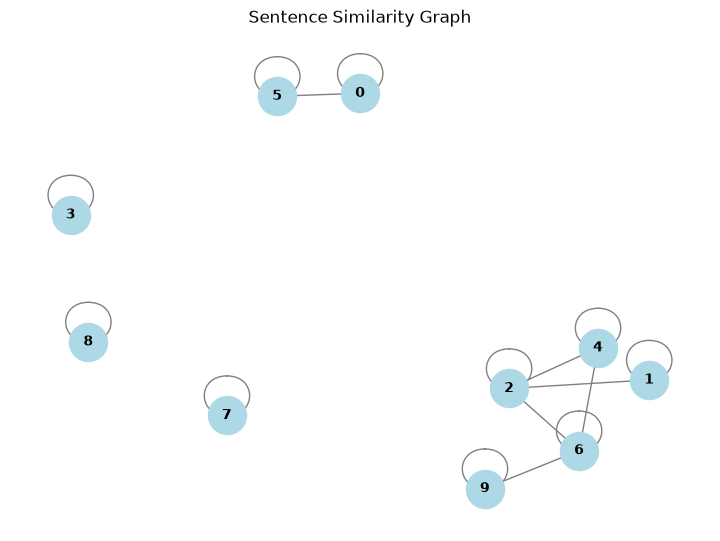

In [6]:
graph = nx.from_numpy_array(similarity_matrix)

plt.figure(figsize=(7, 5))
pos = nx.spring_layout(graph, seed=42)
nx.draw(graph, pos, with_labels=True, node_color='lightblue', node_size=750, edge_color='gray', font_size=10, font_weight='bold')
plt.title("Sentence Similarity Graph")
plt.show()

## 7. Applying PageRank and Generating Extractive Summary


In [7]:
scores = nx.pagerank(graph)

ranked_sentences = sorted(((scores[i], i) for i in range(len(sentences))), reverse=True)

top_indices = sorted([idx for score, idx in ranked_sentences[:3]])
extractive_summary = " ".join([sentences[i] for i in top_indices])

print("PageRank Scores per Sentence:")
for idx, score in sorted(scores.items()):
    print(f"Sentence {idx + 1}: {score:.4f}")

print()
print("Top 3 Selected Sentences:")
for idx in top_indices:
    print(f"- Sentence {idx + 1} (Score: {scores[idx]:.4f}): {sentences[idx]}")

print()
print("Generated Extractive Summary:")
print(extractive_summary)

PageRank Scores per Sentence:
Sentence 1: 0.1000
Sentence 2: 0.0985
Sentence 3: 0.1018
Sentence 4: 0.1000
Sentence 5: 0.0987
Sentence 6: 0.1000
Sentence 7: 0.1027
Sentence 8: 0.1000
Sentence 9: 0.1000
Sentence 10: 0.0983

Top 3 Selected Sentences:
- Sentence 3 (Score: 0.1018): The financial sector utilizes predictive models to detect fraudulent transactions and optimize investment portfolios in real time.
- Sentence 7 (Score: 0.1027): Many models operate as black boxes, making it difficult for researchers to interpret their decision-making processes.
- Sentence 9 (Score: 0.1000): Ensuring transparency, fairness, and accountability in AI development is essential for building public trust.

Generated Extractive Summary:
The financial sector utilizes predictive models to detect fraudulent transactions and optimize investment portfolios in real time. Many models operate as black boxes, making it difficult for researchers to interpret their decision-making processes. Ensuring transparency, 

## 8. Abstractive Text Summarization Using Pretrained Transformer


In [8]:
abstractive_pipeline = pipeline("summarization", model="sshleifer/distilbart-cnn-12-6")
abstractive_result = abstractive_pipeline(text, max_length=60, min_length=25, do_sample=False)
abstractive_summary = abstractive_result[0]['summary_text'].strip()

print("Generated Abstractive Summary:")
print(abstractive_summary)

Device set to use mps:0


Generated Abstractive Summary:
Artificial intelligence has transformed numerous industries by automating tasks that previously required human cognition . The rapid advancement of artificial intelligence raises ethical concerns regarding data privacy and algorithmic bias . Ensuring transparency, fairness, and accountability in AI development is essential for building public trust .


## 9. Comparison of Extractive and Abstractive Summaries

In [9]:
print("=" * 80)
print("ORIGINAL TEXT:")
print("=" * 80)
print(text)

print()
print("=" * 80)
print("EXTRACTIVE SUMMARY (Graph-Based TextRank / PageRank):")
print("=" * 80)
print(extractive_summary)

print()
print("=" * 80)
print("ABSTRACTIVE SUMMARY (Pretrained DistilBART Transformer):")
print("=" * 80)
print(abstractive_summary)
print("=" * 80)

ORIGINAL TEXT:
Artificial intelligence has transformed numerous industries by automating tasks that previously required human cognition. In healthcare, machine learning algorithms analyze medical images to detect diseases at earlier stages than traditional diagnostics. The financial sector utilizes predictive models to detect fraudulent transactions and optimize investment portfolios in real time. Autonomous vehicles rely on computer vision and sensor fusion to navigate complex road environments safely. Natural language processing models power chatbots and translation tools, enabling smoother communication across linguistic boundaries. However, the rapid advancement of artificial intelligence raises ethical concerns regarding data privacy and algorithmic bias. Many models operate as black boxes, making it difficult for researchers to interpret their decision-making processes. Job displacement remains another significant challenge as automation impacts various segments of the workforce.